In [1]:
print("Bienvenue dans mon projet de tarification automobile")

Bienvenue dans mon projet de tarification automobile


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Toutes les bibliothèques sont installées !")

Toutes les bibliothèques sont installées !


In [3]:
from sklearn.datasets import fetch_openml
import pandas as pd

# Télécharger les données réelles
data = fetch_openml(
    data_id=41214,
    as_frame=True,
    target_column=None
)

df = data.frame

# Afficher les premières observations
display(df.head())

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


In [4]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 678013
Nombre de colonnes : 12


In [5]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)

df.to_csv("data/freMTPL2freq.csv", index=False)

print("Dataset enregistré avec succès !")

Dataset enregistré avec succès !


In [6]:
import pandas as pd

df = pd.read_csv("data/freMTPL2freq.csv")

print("Dimensions :", df.shape)
display(df.head())

Dimensions : (678013, 12)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  float64
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   Area        678013 non-null  str    
 4   VehPower    678013 non-null  int64  
 5   VehAge      678013 non-null  int64  
 6   DrivAge     678013 non-null  int64  
 7   BonusMalus  678013 non-null  int64  
 8   VehBrand    678013 non-null  str    
 9   VehGas      678013 non-null  str    
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  str    
dtypes: float64(2), int64(6), str(4)
memory usage: 62.1 MB


In [8]:
df.isnull().sum()

IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0
dtype: int64

In [9]:
df.describe()

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,6.780130e+05,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,2.621857e+06,0.053247,0.528750,6.454631,7.044265,45.499122,59.761502,1792.422405
std,1.641783e+06,0.240117,0.364442,2.050906,5.666232,14.137444,15.636658,3958.646564
min,1.000000e+00,0.000000,0.002732,4.000000,0.000000,18.000000,50.000000,1.000000
25%,1.157951e+06,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000
50%,2.272152e+06,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000
75%,4.046274e+06,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000
max,6.114330e+06,16.000000,2.010000,15.000000,100.000000,100.000000,230.000000,27000.000000


In [10]:
print("Doublons IDpol :", df["IDpol"].duplicated().sum())

print("Expositions nulles ou négatives :",
      (df["Exposure"] <= 0).sum())

print("Expositions supérieures à 1 an :",
      (df["Exposure"] > 1).sum())

print("Sinistres négatifs :",
      (df["ClaimNb"] < 0).sum())

Doublons IDpol : 0
Expositions nulles ou négatives : 0
Expositions supérieures à 1 an : 1224
Sinistres négatifs : 0


In [11]:
# Créer une copie des données originales
df_clean = df.copy()

print("Avant nettoyage :", df.shape)
print("Copie créée :", df_clean.shape)

Avant nettoyage : (678013, 12)
Copie créée : (678013, 12)


In [12]:
# Vérifier les valeurs manquantes
print(df_clean.isnull().sum())

# Convertir les variables essentielles en nombres
df_clean["Exposure"] = pd.to_numeric(
    df_clean["Exposure"], errors="coerce"
)

df_clean["ClaimNb"] = pd.to_numeric(
    df_clean["ClaimNb"], errors="coerce"
)

# Supprimer les lignes sans données essentielles
df_clean = df_clean.dropna(
    subset=["Exposure", "ClaimNb"]
)

# Garder uniquement les valeurs valides
df_clean = df_clean[
    (df_clean["Exposure"] > 0) &
    (df_clean["ClaimNb"] >= 0) &
    (df_clean["ClaimNb"] % 1 == 0)
].copy()

print("Après filtrage :", df_clean.shape)

IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0
dtype: int64
Après filtrage : (678013, 12)


In [13]:
# Compter les valeurs extrêmes avant traitement
print("Exposure > 1 :", (df_clean["Exposure"] > 1).sum())
print("ClaimNb > 4 :", (df_clean["ClaimNb"] > 4).sum())

# Appliquer les plafonds
df_clean["Exposure"] = df_clean["Exposure"].clip(upper=1)
df_clean["ClaimNb"] = df_clean["ClaimNb"].clip(upper=4)

print("Plafonnement terminé !")


Exposure > 1 : 1224
ClaimNb > 4 : 9
Plafonnement terminé !


In [14]:
# Vérifier les identifiants répétés
print("IDpol dupliqués :",
      df_clean["IDpol"].duplicated().sum())

IDpol dupliqués : 0


In [15]:
# Calcul de la fréquence observée
df_clean["Frequence"] = (
    df_clean["ClaimNb"] / df_clean["Exposure"]
)

# Afficher les résultats
display(
    df_clean[["IDpol", "Exposure", "ClaimNb", "Frequence"]].head()
)

,IDpol,Exposure,ClaimNb,Frequence
0,1.0,0.10,1,10.000000
1,3.0,0.77,1,1.298701
2,5.0,0.75,1,1.333333
3,10.0,0.09,1,11.111111
4,11.0,0.84,1,1.190476


In [16]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)

df_clean.to_csv(
    "data/freMTPL2freq_clean.csv",
    index=False
)

print("Données nettoyées enregistrées !")
print("Dimensions finales :", df_clean.shape)

Données nettoyées enregistrées !
Dimensions finales : (678013, 13)


In [17]:
import pandas as pd

# Charger les données nettoyées
df_clean = pd.read_csv("data/freMTPL2freq_clean.csv")

# Calcul des indicateurs
nb_contrats = len(df_clean)
nb_sinistres = df_clean["ClaimNb"].sum()
exposition = df_clean["Exposure"].sum()

frequence = nb_sinistres / exposition

print("Nombre de contrats :", nb_contrats)
print("Nombre de sinistres :", nb_sinistres)
print("Exposition totale :", round(exposition, 2))
print("Fréquence annuelle :", round(frequence, 4))
print("Sinistres pour 100 contrats-années :", round(frequence * 100, 2))

Nombre de contrats : 678013
Nombre de sinistres : 36056
Exposition totale : 358360.11
Fréquence annuelle : 0.1006
Sinistres pour 100 contrats-années : 10.06


In [18]:
# Créer les tranches d'âge
df_clean["TrancheAge"] = pd.cut(
    df_clean["DrivAge"],
    bins=[0, 25, 35, 45, 55, 65, float("inf")],
    labels=[
        "Moins de 25",
        "25-34",
        "35-44",
        "45-54",
        "55-64",
        "65 et plus"
    ],
    right=False
)

# Calculer les indicateurs par tranche
analyse_age = df_clean.groupby(
    "TrancheAge", observed=True
).agg(
    Contrats=("IDpol", "size"),
    Sinistres=("ClaimNb", "sum"),
    Exposition=("Exposure", "sum")
)

analyse_age["Frequence"] = (
    analyse_age["Sinistres"] / analyse_age["Exposition"]
)

display(analyse_age)

,Contrats,Sinistres,Exposition,Frequence
TrancheAge,,,,
Moins de 25,30198,2364,12488.891085,0.189288
25-34,140947,6396,64572.594437,0.099051
35-44,170578,8145,87349.662517,0.093246
45-54,164034,9475,89814.326483,0.105495
55-64,99094,5124,56157.391112,0.091244
65 et plus,73162,4552,47977.239831,0.094878


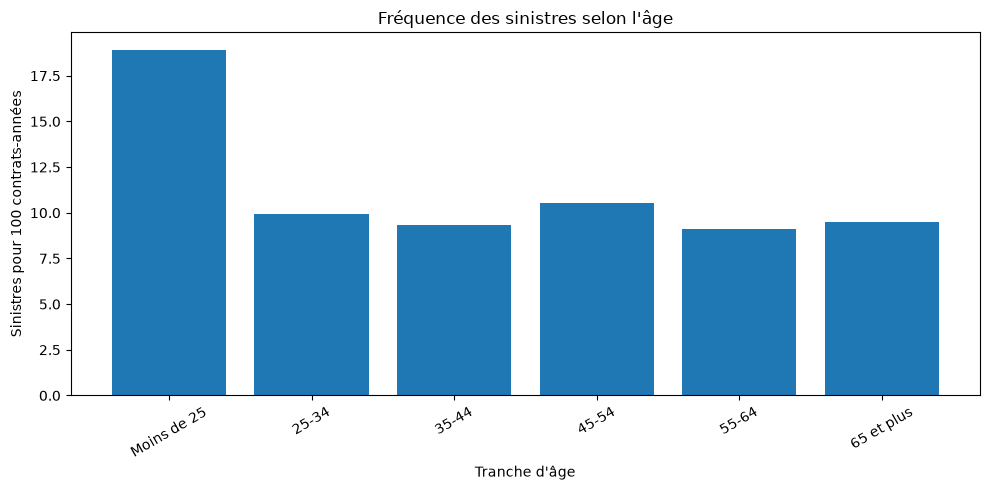

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    analyse_age.index.astype(str),
    analyse_age["Frequence"] * 100
)

plt.title("Fréquence des sinistres selon l'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Sinistres pour 100 contrats-années")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Interprétation : les conducteurs de moins de 25 ans présentent la fréquence la plus élevée, avec 18,93 sinistres pour 100 contrats-années. Cela représente environ le double de la fréquence observée chez les 55–64 ans.

In [20]:
# Créer des classes de bonus-malus
df_clean["ClasseBM"] = pd.cut(
    df_clean["BonusMalus"],
    bins=[float("-inf"), 70, 100, 130, float("inf")],
    labels=["≤70", "71-100", "101-130", ">130"]
)

# Calcul de la fréquence par classe
analyse_bm = df_clean.groupby(
    "ClasseBM", observed=True
).agg(
    Sinistres=("ClaimNb", "sum"),
    Exposition=("Exposure", "sum")
)

analyse_bm["Frequence"] = (
    analyse_bm["Sinistres"] / analyse_bm["Exposition"]
)

display(analyse_bm)

,Sinistres,Exposition,Frequence
ClasseBM,,,
≤70,26234,299595.201416,0.087565
71-100,8480,55194.175045,0.153639
101-130,1181,3208.006094,0.368141
>130,161,362.722909,0.443865


Interprétation : la fréquence observée augmente avec les classes de bonus-malus. Toutefois, la dernière classe possède une exposition relativement faible, donc son estimation est moins précise.

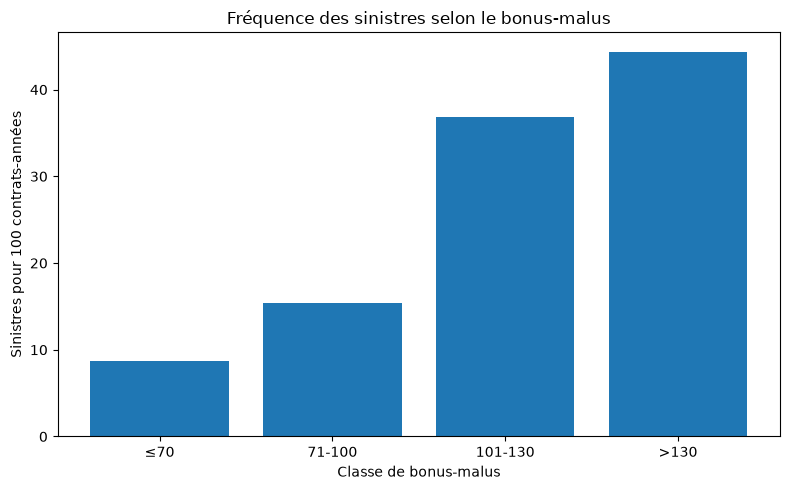

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(
    analyse_bm.index.astype(str),
    analyse_bm["Frequence"] * 100
)

plt.title("Fréquence des sinistres selon le bonus-malus")
plt.xlabel("Classe de bonus-malus")
plt.ylabel("Sinistres pour 100 contrats-années")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.model_selection import train_test_split

# Sélectionner 100 000 contrats pour le premier test
df_ml = df_clean.sample(
    n=100_000,
    random_state=42
).copy()

# Variables explicatives
variables = [
    "DrivAge",
    "VehAge",
    "VehPower",
    "BonusMalus",
    "Density"
]

X = df_ml[variables]

# Variable cible : fréquence observée
y = df_ml["ClaimNb"] / df_ml["Exposure"]

# Poids : durée d'exposition
poids = df_ml["Exposure"]

# Séparer les données
X_train, X_test, y_train, y_test, poids_train, poids_test = train_test_split(
    X, y, poids,
    test_size=0.2,
    random_state=42
)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (80000, 5)
Test : (20000, 5)


In [24]:
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Construire le modèle
model_poisson = Pipeline([
    ("standardisation", StandardScaler()),
    ("poisson", PoissonRegressor(
        alpha=1.0,
        max_iter=500
    ))
])

# Entraîner le modèle
model_poisson.fit(
    X_train,
    y_train,
    poisson__sample_weight=poids_train
)

print("Modèle de Poisson entraîné avec succès !")

Modèle de Poisson entraîné avec succès !


In [26]:
# Prédire la fréquence des sinistres
y_pred = model_poisson.predict(X_test)

# Afficher les 5 premières prédictions
print(y_pred[:5])

[0.101907   0.11029036 0.1017202  0.09518489 0.10297435]


In [28]:
import numpy as np
from sklearn.metrics import mean_poisson_deviance

# Fréquence moyenne du portefeuille d'entraînement
freq_reference = np.average(
    y_train,
    weights=poids_train
)

# Prédictions de référence
pred_reference = np.full(
    len(y_test),
    freq_reference
)

# Déviance du modèle
deviance_modele = mean_poisson_deviance(
    y_test,
    y_pred,
    sample_weight=poids_test
)

# Déviance de référence
deviance_reference = mean_poisson_deviance(
    y_test,
    pred_reference,
    sample_weight=poids_test
)

print("Déviance du modèle :", round(deviance_modele, 4))
print("Déviance de référence :", round(deviance_reference, 4))

print(
    "Modèle meilleur que la référence :",
    deviance_modele < deviance_reference
)

Déviance du modèle : 0.639
Déviance de référence : 0.6421
Modèle meilleur que la référence : True


In [29]:

from sklearn.datasets import fetch_openml

# Télécharger le dataset des montants
data_sev = fetch_openml(
    data_id=41215,
    as_frame=True,
    target_column=None
)

df_sev = data_sev.frame

print("Dimensions :", df_sev.shape)
display(df_sev.head())


Dimensions : (26639, 2)


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


In [30]:

import pandas as pd
import numpy as np

# Préparer les identifiants
df_sev["IDpol"] = df_sev["IDpol"].astype("int64")

# Montant total par contrat
montants = df_sev.groupby("IDpol")["ClaimAmount"].sum()

# Charger la base brute pour conserver le nombre initial
# de sinistres avant plafonnement
df_original = pd.read_csv("data/freMTPL2freq.csv")
df_original["IDpol"] = df_original["IDpol"].astype("int64")

nombres_originaux = df_original.set_index("IDpol")["ClaimNb"]

# Ajouter les informations à notre échantillon ML
df_ml["ClaimAmount"] = (
    df_ml["IDpol"].astype("int64")
    .map(montants).fillna(0)
)

df_ml["ClaimNbOriginal"] = (
    df_ml["IDpol"].astype("int64")
    .map(nombres_originaux)
)

print("Fusion terminée !")
display(df_ml[[
    "IDpol", "ClaimNbOriginal", "ClaimAmount"
]].head())


Fusion terminée !


,IDpol,ClaimNbOriginal,ClaimAmount
261354,2122523.0,0,0.0
448143,3173420.0,0,0.0
188618,1188619.0,0,0.0
12952,31400.0,0,0.0
425028,3138755.0,0,0.0


In [31]:

df_ml["CoutMoyen"] = np.where(
    (df_ml["ClaimNbOriginal"] > 0) &
    (df_ml["ClaimAmount"] > 0),
    df_ml["ClaimAmount"] /
    df_ml["ClaimNbOriginal"].replace(0, np.nan),
    np.nan
)

print("Contrats avec coût positif :",
      df_ml["CoutMoyen"].notna().sum())

display(df_ml[[
    "ClaimNbOriginal", "ClaimAmount", "CoutMoyen"
]].dropna().head())


Contrats avec coût positif : 3735


,ClaimNbOriginal,ClaimAmount,CoutMoyen
360142,1,1204.00,1204.000
127502,2,1289.53,644.765
313507,1,81.33,81.330
588412,1,9742.00,9742.000
389249,1,1204.00,1204.000


In [32]:

from sklearn.linear_model import GammaRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Contrats d'entraînement avec sinistres positifs
train_gamma = df_ml.loc[X_train.index]
train_gamma = train_gamma[
    (train_gamma["ClaimAmount"] > 0) &
    (train_gamma["ClaimNbOriginal"] > 0)
].copy()

# Préparer les variables
X_gamma = train_gamma[variables]
y_gamma = train_gamma["CoutMoyen"]

# Créer le modèle
model_gamma = Pipeline([
    ("standardisation", StandardScaler()),
    ("gamma", GammaRegressor(
        alpha=10.0,
        max_iter=500
    ))
])

# Entraîner, en pondérant par le nombre de sinistres
model_gamma.fit(
    X_gamma,
    y_gamma,
    gamma__sample_weight=train_gamma["ClaimNbOriginal"]
)

print("Modèle Gamma entraîné avec succès !")


Modèle Gamma entraîné avec succès !


In [33]:

# Prédiction sur le jeu de test
cout_predit = model_gamma.predict(X_test)

print("Les 5 premiers coûts moyens prédits :")
print(np.round(cout_predit[:5], 2))


Les 5 premiers coûts moyens prédits :
[2066.44 2063.27 2040.47 1987.92 1974.3 ]


In [34]:

import numpy as np
import pandas as pd

# Prédictions sur les contrats du jeu de test
frequence_predite = model_poisson.predict(X_test)
cout_moyen_predit = model_gamma.predict(X_test)

# Calcul de la prime pure annuelle
prime_pure_predite = (
    frequence_predite * cout_moyen_predit
)

# Présenter les résultats
resultats_primes = pd.DataFrame({
    "Frequence_predite": frequence_predite,
    "CoutMoyen_predit": cout_moyen_predit,
    "PrimePure_predite": prime_pure_predite
}, index=X_test.index)

display(resultats_primes.head(10))


,Frequence_predite,CoutMoyen_predit,PrimePure_predite
37875,0.101907,2066.444511,210.585165
391242,0.110290,2063.272958,227.559112
210653,0.101720,2040.474881,207.557508
128382,0.095185,1987.923922,189.220315
92033,0.102974,1974.302938,203.302558
280099,0.100390,2053.594650,206.160663
338381,0.098645,2048.885791,202.111371
65840,0.100976,2046.465797,206.644579
390210,0.098481,2039.102673,200.812452
57957,0.100947,2064.018865,208.357391


In [35]:

# Récupérer les observations du jeu de test
resultats_primes["Exposure"] = df_ml.loc[
    X_test.index, "Exposure"
]

resultats_primes["ClaimAmount"] = df_ml.loc[
    X_test.index, "ClaimAmount"
]

# Prime pure observée par année d'exposition
resultats_primes["PrimePure_observee"] = (
    resultats_primes["ClaimAmount"] /
    resultats_primes["Exposure"]
)

# Coût total prédit sur la durée du contrat
resultats_primes["Montant_predit"] = (
    resultats_primes["PrimePure_predite"] *
    resultats_primes["Exposure"]
)

display(resultats_primes.head(10))


,Frequence_predite,CoutMoyen_predit,PrimePure_predite,Exposure,ClaimAmount,PrimePure_observee,Montant_predit
37875,0.101907,2066.444511,210.585165,0.25,0.00,0.000000,52.646291
391242,0.110290,2063.272958,227.559112,0.16,0.00,0.000000,36.409458
210653,0.101720,2040.474881,207.557508,0.95,0.00,0.000000,197.179633
128382,0.095185,1987.923922,189.220315,0.47,0.00,0.000000,88.933548
92033,0.102974,1974.302938,203.302558,0.21,0.00,0.000000,42.693537
280099,0.100390,2053.594650,206.160663,0.07,0.00,0.000000,14.431246
338381,0.098645,2048.885791,202.111371,0.83,0.00,0.000000,167.752438
65840,0.100976,2046.465797,206.644579,0.14,0.00,0.000000,28.930241
390210,0.098481,2039.102673,200.812452,0.41,0.00,0.000000,82.333105
57957,0.100947,2064.018865,208.357391,0.58,607.66,1047.689655,120.847287


In [36]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_tweedie_deviance
)

# Référence : prime pure moyenne de l'entraînement
prime_reference = (
    df_ml.loc[X_train.index, "ClaimAmount"].sum() /
    df_ml.loc[X_train.index, "Exposure"].sum()
)

y_reel = resultats_primes["PrimePure_observee"]
y_modele = resultats_primes["PrimePure_predite"]
y_reference = np.full(len(y_reel), prime_reference)
poids = resultats_primes["Exposure"]

# Erreur absolue moyenne pondérée
mae_modele = mean_absolute_error(
    y_reel, y_modele, sample_weight=poids
)
mae_reference = mean_absolute_error(
    y_reel, y_reference, sample_weight=poids
)

# Déviance Tweedie
dev_modele = mean_tweedie_deviance(
    y_reel, y_modele,
    sample_weight=poids, power=1.5
)

dev_reference = mean_tweedie_deviance(
    y_reel, y_reference,
    sample_weight=poids, power=1.5
)

print("MAE modèle :", round(mae_modele, 2))
print("MAE référence :", round(mae_reference, 2))
print("Déviance modèle :", round(dev_modele, 4))
print("Déviance référence :", round(dev_reference, 4))


MAE modèle : 323.81
MAE référence : 278.82
Déviance modèle : 79.343
Déviance référence : 78.4012


In [37]:

cout_total_reel = resultats_primes["ClaimAmount"].sum()

cout_total_predit = resultats_primes["Montant_predit"].sum()

print("Coût total réel :", round(cout_total_reel, 2), "€")
print("Coût total prédit :", round(cout_total_predit, 2), "€")

ecart = (
    (cout_total_predit - cout_total_reel) /
    cout_total_reel * 100
)

print("Écart relatif :", round(ecart, 2), "%")


Coût total réel : 1505251.29 €
Coût total prédit : 2122840.03 €
Écart relatif : 41.03 %


,Exposition,Cout_reel,Cout_predit,Prime_observee,Prime_predite
Decile,,,,,
1,1396.023898,131212.29,259540.012871,93.990003,185.913732
2,1298.091021,133680.66,249833.584570,102.982501,192.462301
3,1298.325641,125343.66,254572.555690,96.542544,196.077585
4,1169.177611,101614.30,232725.176690,86.910918,199.050319
5,1087.703853,115668.37,219089.366091,106.341786,201.423729
6,1009.479614,101375.32,205480.675747,100.423345,203.551090
7,905.980595,161767.61,186353.032378,178.555270,205.692079
8,829.784249,193583.89,173228.430949,233.294245,208.763219
9,802.961380,168443.82,172078.229542,209.778234,214.304491


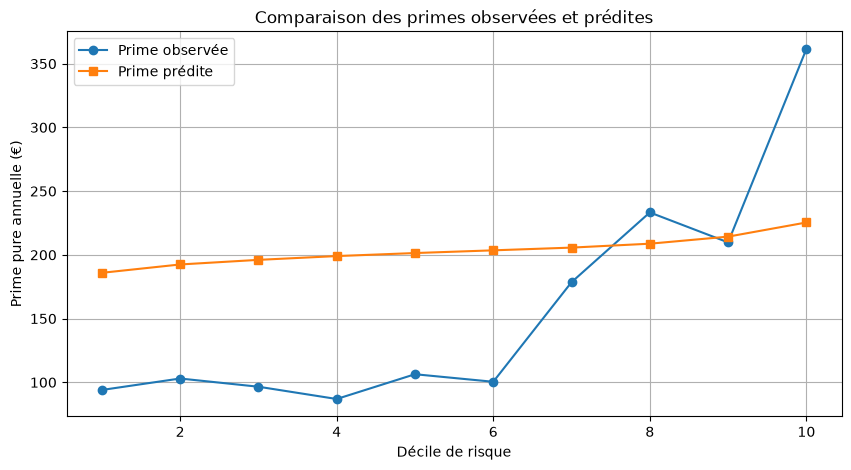

In [38]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Copier les résultats du jeu de test
df_graph = resultats_primes.copy()

# Répartir les contrats en 10 groupes de risque
df_graph["Decile"] = pd.qcut(
    df_graph["PrimePure_predite"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

# Calculer les résultats par groupe
analyse_risque = df_graph.groupby("Decile").agg(
    Exposition=("Exposure", "sum"),
    Cout_reel=("ClaimAmount", "sum"),
    Cout_predit=("Montant_predit", "sum")
)

# Prime pure par année d'exposition
analyse_risque["Prime_observee"] = (
    analyse_risque["Cout_reel"] /
    analyse_risque["Exposition"]
)

analyse_risque["Prime_predite"] = (
    analyse_risque["Cout_predit"] /
    analyse_risque["Exposition"]
)

display(analyse_risque)

# Graphique de comparaison
plt.figure(figsize=(10, 5))

plt.plot(
    analyse_risque.index,
    analyse_risque["Prime_observee"],
    marker="o",
    label="Prime observée"
)

plt.plot(
    analyse_risque.index,
    analyse_risque["Prime_predite"],
    marker="s",
    label="Prime prédite"
)

plt.xlabel("Décile de risque")
plt.ylabel("Prime pure annuelle (€)")
plt.title("Comparaison des primes observées et prédites")
plt.legend()
plt.grid(True)
plt.show()


In [39]:
from pathlib import Path

Path("resultats").mkdir(exist_ok=True)

analyse_risque.to_csv(
    "resultats/analyse_risque.csv"
)

resultats_primes.to_csv(
    "resultats/predictions_primes.csv",
    index=False
)

print("Résultats enregistrés avec succès !")

Résultats enregistrés avec succès !


In [40]:

import joblib
from pathlib import Path

# Créer un dossier pour les modèles
Path("modeles").mkdir(exist_ok=True)

# Enregistrer les modèles et les variables
joblib.dump(
    {
        "poisson": model_poisson,
        "gamma": model_gamma,
        "variables": variables
    },
    "modeles/tarification.joblib"
)

print("Modèles enregistrés avec succès !")


Modèles enregistrés avec succès !


In [42]:
# Résumé des performances du modèle

print("=== ÉVALUATION FINALE ===")

print("MAE du modèle :", round(mae_modele, 2))
print("MAE de référence :", round(mae_reference, 2))

print("Déviance Tweedie du modèle :", round(dev_modele, 4))
print("Déviance Tweedie de référence :", round(dev_reference, 4))

print("Coût réel total :", round(cout_total_reel, 2))
print("Coût prédit total :", round(cout_total_predit, 2))

=== ÉVALUATION FINALE ===
MAE du modèle : 323.81
MAE de référence : 278.82
Déviance Tweedie du modèle : 79.343
Déviance Tweedie de référence : 78.4012
Coût réel total : 1505251.29
Coût prédit total : 2122840.03


In [43]:

# Vérification des données utilisées par les modèles

print("=== CONTROLE DES DONNEES ===")

print("Nombre de contrats :", len(df_ml))

print(
    "Contrats dont le nombre de sinistres a été modifié :",
    (df_ml["ClaimNb"] != df_ml["ClaimNbOriginal"]).sum()
)

print(
    "Contrats avec sinistre mais sans montant positif :",
    ((df_ml["ClaimNbOriginal"] > 0) &
     (df_ml["ClaimAmount"] <= 0)).sum()
)

print(
    "Contrats sans sinistre mais avec montant positif :",
    ((df_ml["ClaimNbOriginal"] == 0) &
     (df_ml["ClaimAmount"] > 0)).sum()
)

# Comparaison des portefeuilles
for nom, indices in [
    ("Entraînement", X_train.index),
    ("Test", X_test.index)
]:
    partie = df_ml.loc[indices]

    freq = (
        partie["ClaimNbOriginal"].sum() /
        partie["Exposure"].sum()
    )

    prime = (
        partie["ClaimAmount"].sum() /
        partie["Exposure"].sum()
    )

    print(f"\n{nom}")
    print("Fréquence annuelle :", round(freq, 4))
    print("Prime pure observée :", round(prime, 2), "€")


=== CONTROLE DES DONNEES ===
Nombre de contrats : 100000
Contrats dont le nombre de sinistres a été modifié : 1
Contrats avec sinistre mais sans montant positif : 1262
Contrats sans sinistre mais avec montant positif : 0

Entraînement
Fréquence annuelle : 0.0993
Prime pure observée : 151.2 €

Test
Fréquence annuelle : 0.1044
Prime pure observée : 142.66 €


In [44]:

import numpy as np

# Copier les données pour conserver l'ancienne version
df_ml_corr = df_ml.copy()

# Harmoniser le nombre de sinistres avec les montants
df_ml_corr["ClaimNbCorrige"] = np.where(
    df_ml_corr["ClaimAmount"] > 0,
    df_ml_corr["ClaimNbOriginal"],
    0
)

# Recalculer la fréquence
df_ml_corr["FrequenceCorrigee"] = (
    df_ml_corr["ClaimNbCorrige"] /
    df_ml_corr["Exposure"]
)

# Recalculer le coût moyen pour les sinistres positifs
df_ml_corr["CoutMoyenCorrige"] = np.where(
    df_ml_corr["ClaimNbCorrige"] > 0,
    df_ml_corr["ClaimAmount"] /
    df_ml_corr["ClaimNbCorrige"].replace(0, np.nan),
    np.nan
)

print("=== DONNEES HARMONISEES ===")

print(
    "Contrats corrigés :",
    (df_ml_corr["ClaimNbOriginal"] !=
     df_ml_corr["ClaimNbCorrige"]).sum()
)

print(
    "Nouvelle fréquence annuelle :",
    round(
        df_ml_corr["ClaimNbCorrige"].sum() /
        df_ml_corr["Exposure"].sum(), 4
    )
)

display(df_ml_corr[[
    "ClaimNbOriginal",
    "ClaimNbCorrige",
    "ClaimAmount",
    "FrequenceCorrigee",
    "CoutMoyenCorrige"
]].head())


=== DONNEES HARMONISEES ===
Contrats corrigés : 1262
Nouvelle fréquence annuelle : 0.0751


,ClaimNbOriginal,ClaimNbCorrige,ClaimAmount,FrequenceCorrigee,CoutMoyenCorrige
261354,0,0,0.0,0.0,NaN
448143,0,0,0.0,0.0,NaN
188618,0,0,0.0,0.0,NaN
12952,0,0,0.0,0.0,NaN
425028,0,0,0.0,0.0,NaN


In [45]:

from sklearn.linear_model import PoissonRegressor, GammaRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Garder la même séparation train/test
train_corr = df_ml_corr.loc[X_train.index]
test_corr = df_ml_corr.loc[X_test.index]

# Modèle Poisson corrigé
model_poisson_corr = Pipeline([
    ("standardisation", StandardScaler()),
    ("poisson", PoissonRegressor(
        alpha=1.0,
        max_iter=500
    ))
])

model_poisson_corr.fit(
    train_corr[variables],
    train_corr["FrequenceCorrigee"],
    poisson__sample_weight=train_corr["Exposure"]
)

print("Poisson corrigé entraîné !")

# Modèle Gamma corrigé
train_gamma_corr = train_corr[
    (train_corr["ClaimNbCorrige"] > 0) &
    (train_corr["ClaimAmount"] > 0)
].copy()

model_gamma_corr = Pipeline([
    ("standardisation", StandardScaler()),
    ("gamma", GammaRegressor(
        alpha=10.0,
        max_iter=500
    ))
])

model_gamma_corr.fit(
    train_gamma_corr[variables],
    train_gamma_corr["CoutMoyenCorrige"],
    gamma__sample_weight=train_gamma_corr["ClaimNbCorrige"]
)

print("Gamma corrigé entraîné !")


Poisson corrigé entraîné !
Gamma corrigé entraîné !


In [46]:

# Prédictions sur le jeu de test
freq_corr = model_poisson_corr.predict(
    test_corr[variables]
)

cout_corr = model_gamma_corr.predict(
    test_corr[variables]
)

prime_corr = freq_corr * cout_corr

print("Fréquences prédites :", freq_corr[:5])
print("Coûts moyens prédits :", cout_corr[:5])
print("Primes pures prédites :", prime_corr[:5])


Fréquences prédites : [0.07600269 0.08288712 0.07483035 0.07215597 0.07522797]
Coûts moyens prédits : [2066.44451085 2063.2729575  2040.4748813  1987.92392249 1974.30293827]
Primes pures prédites : [157.05535042 171.01875508 152.68944829 143.44057976 148.52280822]


In [47]:

import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_tweedie_deviance
)

# Coût annuel réellement observé
y_reel_corr = (
    test_corr["ClaimAmount"].to_numpy() /
    test_corr["Exposure"].to_numpy()
)

# Poids des contrats
poids_corr = test_corr["Exposure"].to_numpy()

# Prime moyenne de référence sur l'entraînement
prime_ref_corr = (
    train_corr["ClaimAmount"].sum() /
    train_corr["Exposure"].sum()
)

prediction_ref = np.full(
    len(test_corr), prime_ref_corr
)

# MAE
mae_corr = mean_absolute_error(
    y_reel_corr,
    prime_corr,
    sample_weight=poids_corr
)

mae_ref_corr = mean_absolute_error(
    y_reel_corr,
    prediction_ref,
    sample_weight=poids_corr
)

# Déviance Tweedie
dev_corr = mean_tweedie_deviance(
    y_reel_corr,
    prime_corr,
    sample_weight=poids_corr,
    power=1.5
)

dev_ref_corr = mean_tweedie_deviance(
    y_reel_corr,
    prediction_ref,
    sample_weight=poids_corr,
    power=1.5
)

print("=== EVALUATION DU MODELE CORRIGE ===")

print("MAE modèle :", round(mae_corr, 2))
print("MAE référence :", round(mae_ref_corr, 2))

print("Déviance modèle :", round(dev_corr, 4))
print("Déviance référence :", round(dev_ref_corr, 4))

print(
    "Modèle meilleur selon Tweedie :",
    dev_corr < dev_ref_corr
)


=== EVALUATION DU MODELE CORRIGE ===
MAE modèle : 277.84
MAE référence : 278.82
Déviance modèle : 77.8932
Déviance référence : 78.4012
Modèle meilleur selon Tweedie : True


In [48]:

import numpy as np

# Coût total réel du jeu de test
cout_reel_corr = test_corr["ClaimAmount"].sum()

# Coût total prédit par le modèle corrigé
cout_predit_corr = np.sum(
    prime_corr * test_corr["Exposure"].to_numpy()
)

# Écart relatif
ecart_corr = (
    (cout_predit_corr - cout_reel_corr)
    / cout_reel_corr * 100
)

print("=== CALIBRATION DU MODELE CORRIGE ===")

print("Coût réel :", round(cout_reel_corr, 2), "€")
print("Coût prédit :", round(cout_predit_corr, 2), "€")
print("Écart relatif :", round(ecart_corr, 2), "%")


=== CALIBRATION DU MODELE CORRIGE ===
Coût réel : 1505251.29 €
Coût prédit : 1586318.56 €
Écart relatif : 5.39 %


In [49]:

import joblib
from pathlib import Path

# Créer le dossier si nécessaire
Path("modeles").mkdir(exist_ok=True)

# Enregistrer les nouveaux modèles
joblib.dump(
    {
        "poisson": model_poisson_corr,
        "gamma": model_gamma_corr,
        "variables": variables
    },
    "modeles/tarification_corrigee.joblib"
)

print("Modèles corrigés enregistrés avec succès !")


Modèles corrigés enregistrés avec succès !


In [50]:

import numpy as np

# Coût réel des sinistres
cout_reel = test_corr["ClaimAmount"].sum()

# Coût total prédit
cout_predit = np.sum(
    prime_corr * test_corr["Exposure"].to_numpy()
)

# Écart relatif
ecart = (cout_predit - cout_reel) / cout_reel * 100

print("=== CALIBRATION FINALE ===")

print("Coût réel :", round(cout_reel, 2), "€")
print("Coût prédit :", round(cout_predit, 2), "€")
print("Écart relatif :", round(ecart, 2), "%")


=== CALIBRATION FINALE ===
Coût réel : 1505251.29 €
Coût prédit : 1586318.56 €
Écart relatif : 5.39 %


In [51]:
cout_reel = test_corr["ClaimAmount"].sum()

cout_predit = (
    prime_corr * test_corr["Exposure"].to_numpy()
).sum()

ecart = (cout_predit - cout_reel) / cout_reel * 100

print("Coût réel :", round(cout_reel, 2))
print("Coût prédit :", round(cout_predit, 2))
print("Écart :", round(ecart, 2), "%")

Coût réel : 1505251.29
Coût prédit : 1586318.56
Écart : 5.39 %
